# Codveda Data Analytics Internship - Level 1 (Basic)
**Task 1:** Data Cleaning & Preprocessing  **Task 2:** Exploratory Data Analysis

Set `RAW_PATH` to your own raw CSV to rerun everything on a different dataset
(column names in the cleaning section may need adjusting).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
RAW_PATH = "raw_data.csv"
os.makedirs("plots", exist_ok=True)

## Task 1: Data Cleaning & Preprocessing
### 1. Load the dataset

In [2]:
df = pd.read_csv(RAW_PATH)
print("Shape:", df.shape)
print(df.head(), "\n")
print(df.dtypes)

Shape: (630, 9)
   order_id customer_name   age  ... product_category quantity unit_price
0      1375     Eva Brown  26.0  ...      Electronics      4.0        NaN
1      1453    Carla Diaz  47.0  ...      Electronics      3.0     413.92
2      1107    Carla Diaz  59.0  ...             Home      4.0     212.49
3      1418   alice smith  20.0  ...         Clothing      3.0        NaN
4      1248     BOB JONES  33.0  ...             home      4.0     193.73

[5 rows x 9 columns] 

order_id              int64
customer_name           str
age                 float64
gender                  str
city                    str
order_date              str
product_category        str
quantity                str
unit_price          float64
dtype: object


### 2. Identify missing values and duplicates

In [3]:
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
 order_id             0
customer_name        0
age                 47
gender              32
city                22
order_date          12
product_category     0
quantity            40
unit_price          33
dtype: int64 

Duplicate rows: 30


### 3. Remove duplicates and standardize formats

In [4]:
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n0 - len(df)} duplicate rows")

# text columns: trim whitespace, consistent case
df["customer_name"] = df["customer_name"].str.strip().str.title()
df["city"] = df["city"].str.strip().str.title()
df["product_category"] = df["product_category"].str.strip().str.title()

# categorical: unify gender labels
gender_map = {"m": "Male", "male": "Male", "f": "Female", "female": "Female"}
df["gender"] = df["gender"].str.strip().str.lower().map(gender_map)

# dates: mixed formats -> one datetime format
df["order_date"] = pd.to_datetime(df["order_date"], format="mixed", errors="coerce")

# numeric: coerce non-numeric entries to NaN
for col in ["age", "quantity", "unit_price"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# impossible ages -> missing
df.loc[(df["age"] < 16) | (df["age"] > 100), "age"] = np.nan

Removed 30 duplicate rows


### 4. Handle missing values
- Numeric columns: median imputation (robust to outliers)
- Categorical columns: mode imputation
- Rows missing the order date (key field) are dropped

In [5]:
print("Missing before:\n", df.isna().sum(), "\n")
df = df.dropna(subset=["order_date"])
for col in ["age", "quantity", "unit_price"]:
    df[col] = df[col].fillna(df[col].median())
for col in ["gender", "city", "product_category", "customer_name"]:
    df[col] = df[col].fillna(df[col].mode()[0])
df["age"] = df["age"].round().astype(int)
df["quantity"] = df["quantity"].round().astype(int)
df["total_amount"] = (df["quantity"] * df["unit_price"]).round(2)
print("Missing after:\n", df.isna().sum())

df.to_csv("cleaned_data.csv", index=False)
print("\nCleaned shape:", df.shape)
print(df.head())

Missing before:
 order_id             0
customer_name        0
age                 49
gender              30
city                21
order_date          12
product_category     0
quantity            42
unit_price          30
dtype: int64 

Missing after:
 order_id            0
customer_name       0
age                 0
gender              0
city                0
order_date          0
product_category    0
quantity            0
unit_price          0
total_amount        0
dtype: int64

Cleaned shape: (588, 10)
   order_id customer_name  age  ... quantity unit_price total_amount
0      1375     Eva Brown   26  ...        4     92.635       370.54
1      1453    Carla Diaz   47  ...        3    413.920      1241.76
2      1107    Carla Diaz   59  ...        4    212.490       849.96
3      1418   Alice Smith   20  ...        3     92.635       277.90
4      1248     Bob Jones   33  ...        4    193.730       774.92

[5 rows x 10 columns]


## Task 2: Exploratory Data Analysis
### 1. Summary statistics

In [6]:
num_cols = ["age", "quantity", "unit_price", "total_amount"]
summary = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T
summary["mode"] = [df[c].mode()[0] for c in num_cols]
print(summary.round(2))
summary.round(2).to_csv("summary_statistics.csv")

                mean  median     std    min      max    mode
age            44.82   45.00   14.06  18.00    69.00   45.00
quantity        2.90    3.00    1.33   1.00     5.00    3.00
unit_price    153.93   92.64  170.55   8.04   697.09   92.64
total_amount  444.74  225.35  566.88   8.93  3470.10  277.90


### 2. Distributions: histograms, boxplots, scatter plot

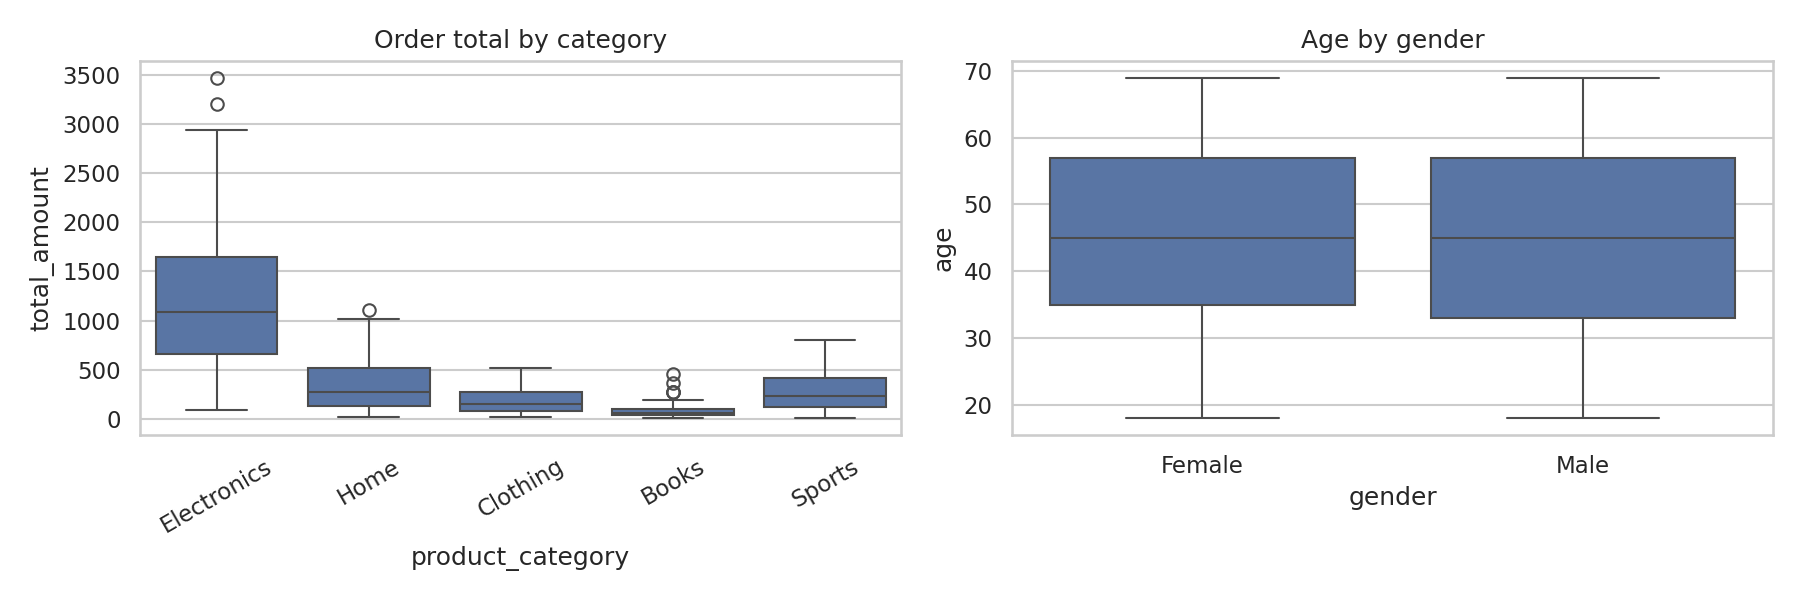

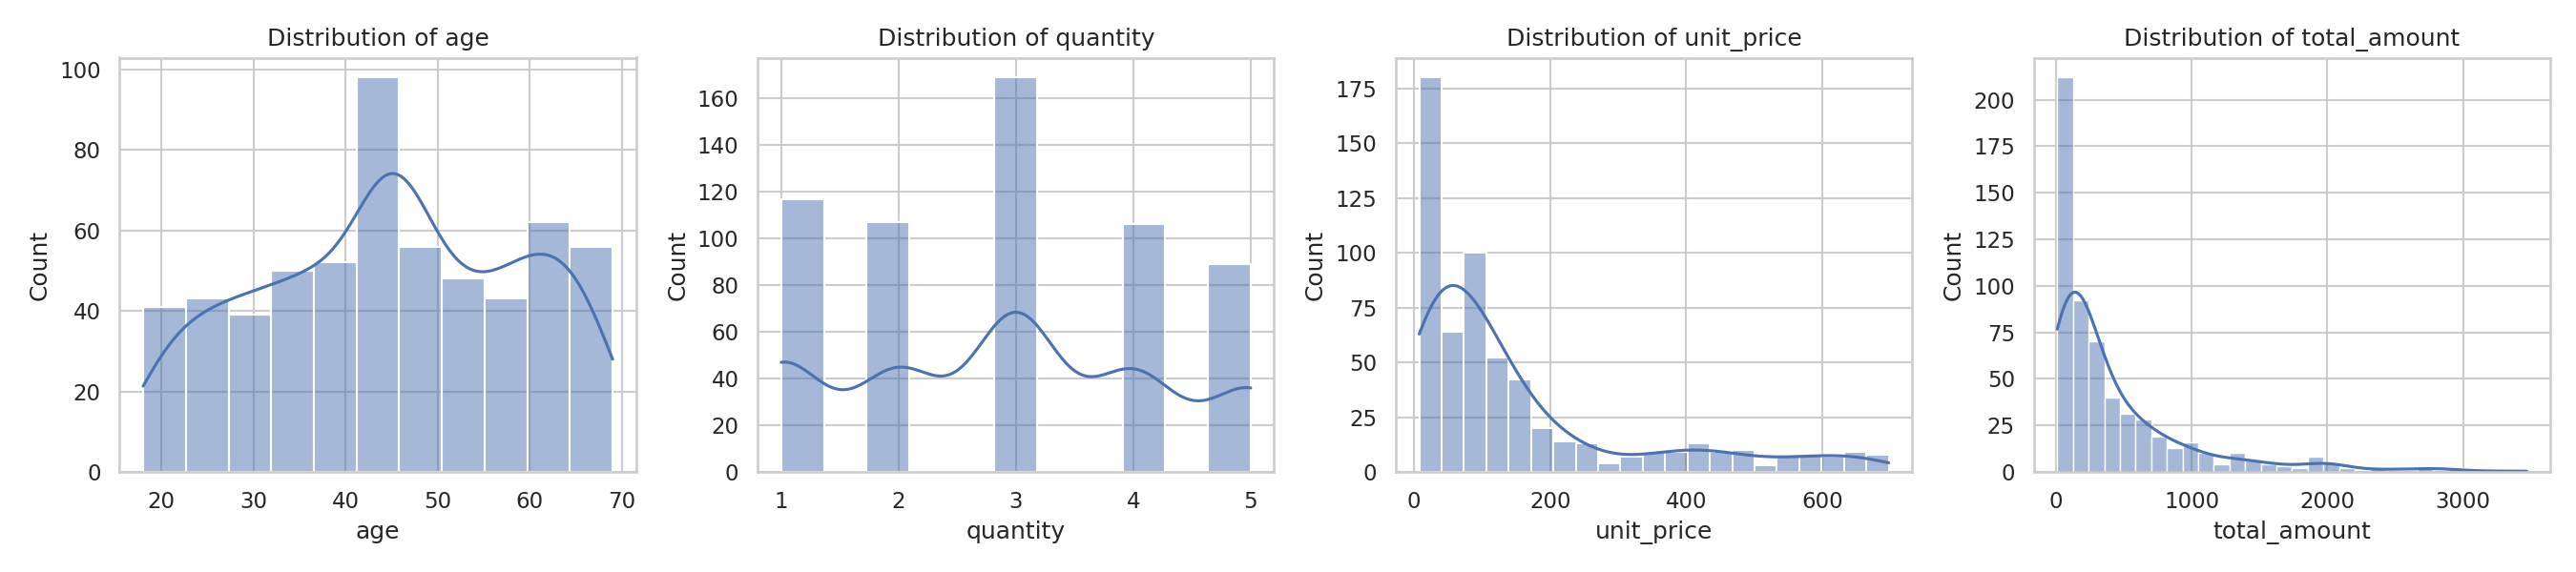

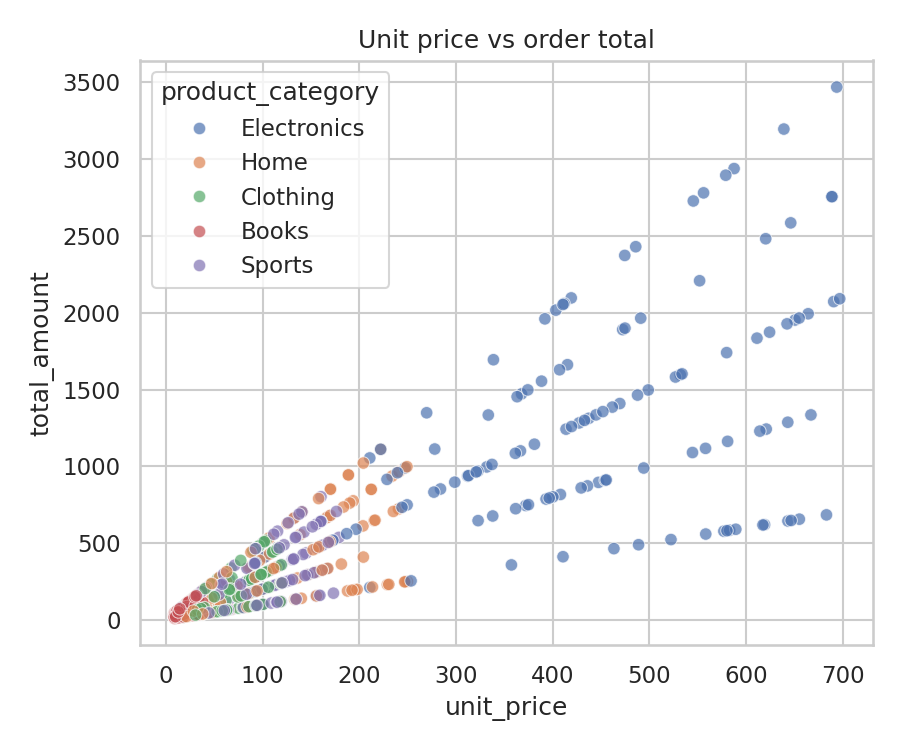

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c], kde=True, ax=ax)
    ax.set_title(f"Distribution of {c}")
plt.tight_layout(); plt.savefig("plots/histograms.png", dpi=150); plt.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="product_category", y="total_amount", ax=axes[0])
axes[0].set_title("Order total by category"); axes[0].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="gender", y="age", ax=axes[1])
axes[1].set_title("Age by gender")
plt.tight_layout(); plt.savefig("plots/boxplots.png", dpi=150); plt.close()

plt.figure(figsize=(6, 5))
sns.scatterplot(data=df, x="unit_price", y="total_amount", hue="product_category", alpha=0.7)
plt.title("Unit price vs order total")
plt.tight_layout(); plt.savefig("plots/scatter.png", dpi=150); plt.close()

### 3. Correlations between numerical features

               age  quantity  unit_price  total_amount
age           1.00     -0.05        0.00         -0.03
quantity     -0.05      1.00       -0.01          0.34
unit_price    0.00     -0.01        1.00          0.85
total_amount -0.03      0.34        0.85          1.00


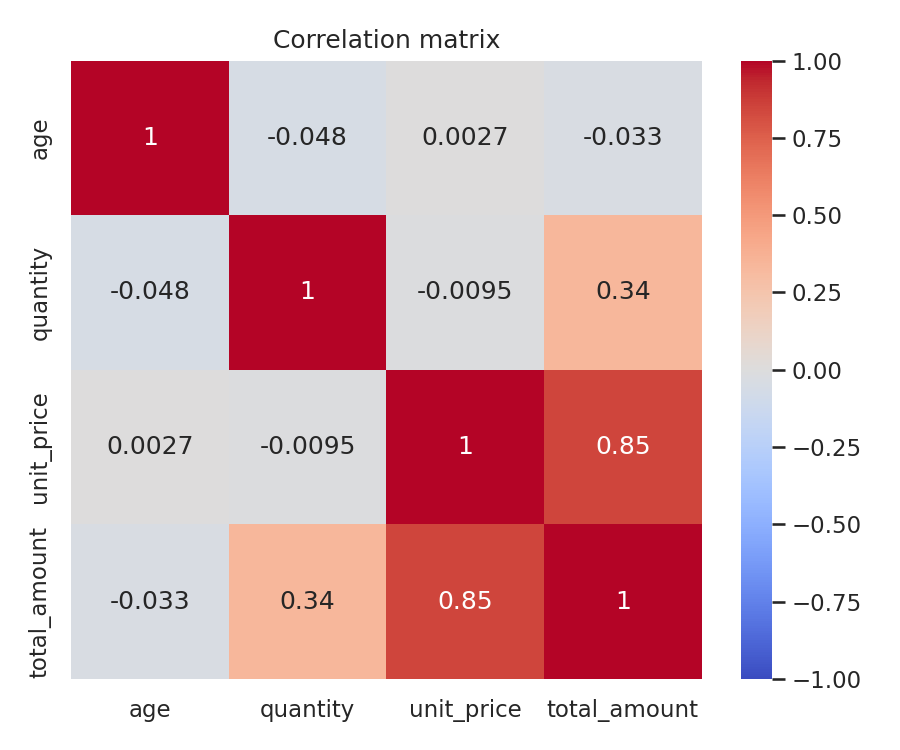

In [8]:
corr = df[num_cols].corr()
print(corr.round(2))
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout(); plt.savefig("plots/correlation_heatmap.png", dpi=150); plt.close()

### 4. Trends and patterns

In [9]:
monthly = df.set_index("order_date")["total_amount"].resample("MS").sum()
print(monthly.round(0))
print("\nRevenue by category:\n", df.groupby("product_category")["total_amount"].sum().round(0).sort_values(ascending=False))
print("\nRevenue by city:\n", df.groupby("city")["total_amount"].sum().round(0).sort_values(ascending=False))

order_date
2024-01-01    13873.0
2024-02-01    25270.0
2024-03-01    20412.0
2024-04-01    33897.0
2024-05-01    27064.0
2024-06-01    16388.0
2024-07-01    21280.0
2024-08-01    22136.0
2024-09-01    24726.0
2024-10-01    21004.0
2024-11-01    15603.0
2024-12-01    19853.0
Freq: MS, Name: total_amount, dtype: float64

Revenue by category:
 product_category
Electronics    156973.0
Home            40849.0
Sports          34221.0
Clothing        19259.0
Books           10203.0
Name: total_amount, dtype: float64

Revenue by city:
 city
New York    94746.0
London      68962.0
Paris       68813.0
Berlin      28984.0
Name: total_amount, dtype: float64
